In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Loan DataSet

In [2]:
loan_data = pd.read_csv('loan-train.csv')

In [3]:
loan_data.head(30)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [1]:
import pandas as pd
loan_train = pd.read_csv('loan-train.csv', sep=',', na_values=[''], quotechar='"')
loan_train

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1609,LP009965,Male,No,3+,Graduate,Yes,13658,9822.0,323.0,180.0,0.0,Urban,N
1610,LP009966,Male,Yes,0,Graduate,No,13683,2223.0,182.0,360.0,1.0,Semiurban,Y
1611,LP009970,Male,Yes,3+,Not Graduate,Yes,19409,768.0,222.0,360.0,0.0,Urban,N
1612,LP009977,Female,Yes,2,Graduate,Yes,8997,1354.0,355.0,360.0,0.0,Rural,Y


In [4]:
loan_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   1600 non-null   float64
 10  Credit_History     1564 non-null   float64
 11  Property_Area      1614 non-null   str    
 12  Loan_Status        1614 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 164.1 KB


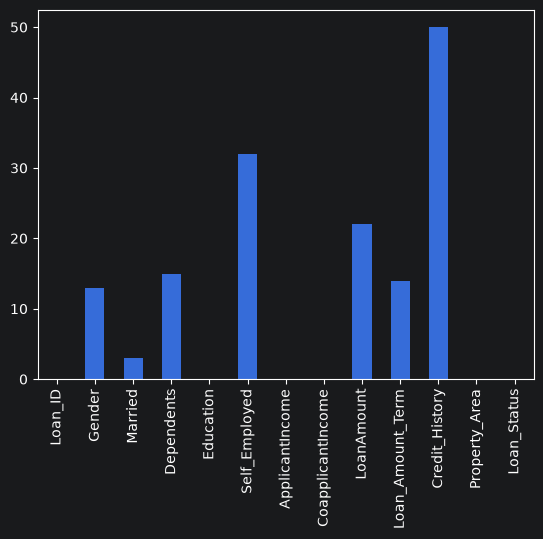

In [5]:
nan_chk = loan_data.isnull().sum()
nan_chk.plot(kind='bar')
plt.show()


# Fixing Null values on Gender Column

In [6]:
loan_data.Gender.isnull().sum()


np.int64(13)

In [7]:
loan_data.Gender

0         Male
1         Male
2         Male
3         Male
4         Male
         ...  
1609      Male
1610      Male
1611      Male
1612    Female
1613    Female
Name: Gender, Length: 1614, dtype: str

In [8]:
loan_data['Gender'].mode()[0]

'Male'

<Axes: xlabel='Gender'>

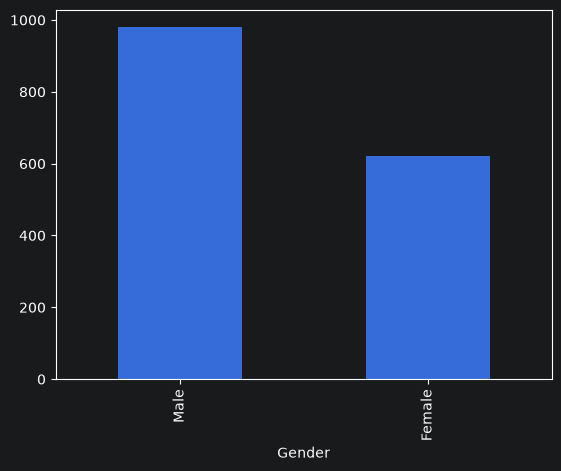

In [9]:
loan_data['Gender'].value_counts().plot(kind='bar')

In [10]:
loan_data['Gender'] = loan_data["Gender"].fillna(loan_data['Gender'].mode()[0])

<Axes: >

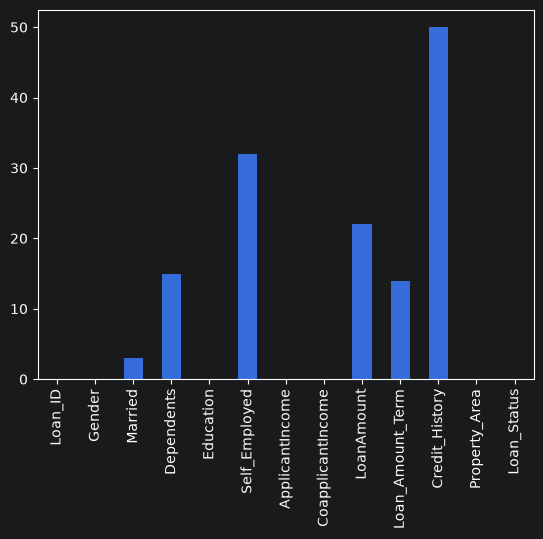

In [11]:
loan_data.isnull().sum().plot(kind="bar")

# Fixing Null values on Married Column

In [12]:
loan_data['Married'].isnull().sum()

np.int64(3)

In [13]:
loan_data["Married"].dtype

<StringDtype(storage='python', na_value=nan)>

In [14]:
loan_data['Married'].mode()[0]

'Yes'

In [15]:
loan_data['Married'] = loan_data['Married'].fillna(loan_data['Married'].mode()[0])

In [16]:
loan_data['Married'].isnull().sum()

np.int64(0)

<Axes: >

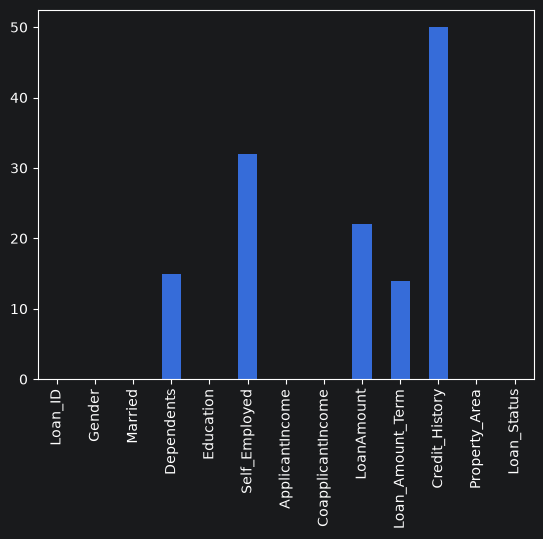

In [17]:
loan_data.isnull().sum().plot(kind="bar")

# Fixing Null values on Dependents Column

In [18]:
loan_data['Dependents'].isnull().sum()

np.int64(15)

In [19]:
loan_data['Dependents'].dtype

<StringDtype(storage='python', na_value=nan)>

In [20]:
loan_data['Dependents']

0        0
1        1
2        0
3        0
4        0
        ..
1609    3+
1610     0
1611    3+
1612     2
1613     2
Name: Dependents, Length: 1614, dtype: str

In [21]:
loan_data['Dependents'].unique()

<StringArray>
['0', '1', '2', '3+', nan]
Length: 5, dtype: str

<Axes: xlabel='Dependents'>

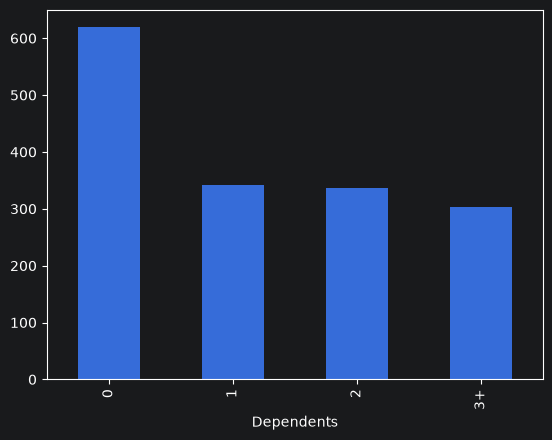

In [22]:
loan_data['Dependents'].value_counts().plot(kind='bar')

In [23]:
loan_data['Dependents'].mode()[0]

'0'

In [24]:
loan_data["Dependents"] = loan_data["Dependents"].fillna(loan_data['Dependents'].mode()[0])

<Axes: >

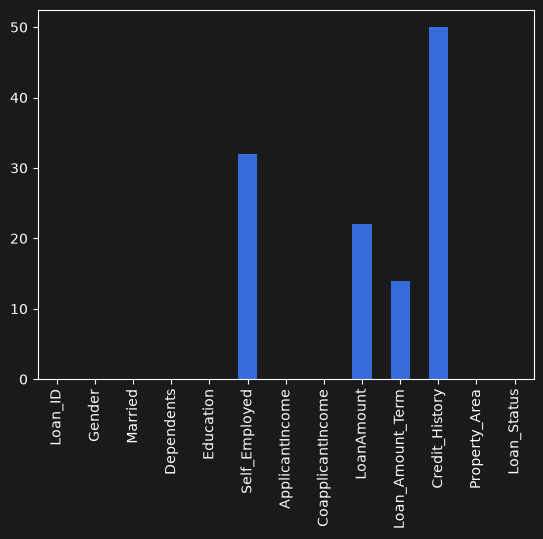

In [25]:
loan_data.isnull().sum().plot(kind="bar")

# Fixing Null values on Self-Employed Column

In [26]:
loan_data['Self_Employed']

0        No
1        No
2       Yes
3        No
4        No
       ... 
1609    Yes
1610     No
1611    Yes
1612    Yes
1613     No
Name: Self_Employed, Length: 1614, dtype: str

In [27]:
loan_data['Self_Employed'].isnull().sum()

np.int64(32)

In [28]:
loan_data['Self_Employed'].dtype

<StringDtype(storage='python', na_value=nan)>

In [29]:
loan_data['Self_Employed'].unique()

<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str

In [30]:
loan_data['Self_Employed'].mode()[0]

'No'

<Axes: xlabel='Self_Employed'>

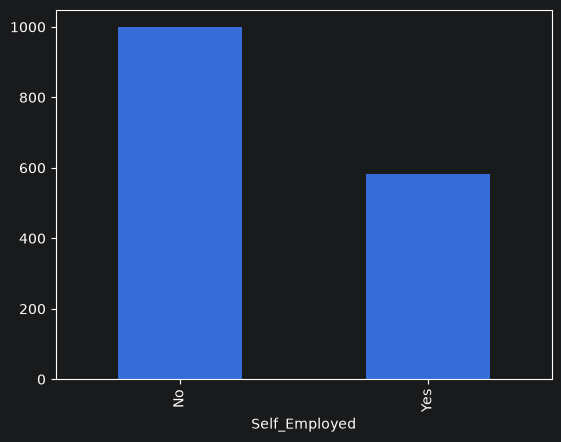

In [31]:
loan_data['Self_Employed'].value_counts().plot(kind='bar')

In [32]:
loan_data['Self_Employed'] =  loan_data['Self_Employed'].fillna(loan_data['Self_Employed'].mode()[0])

<Axes: >

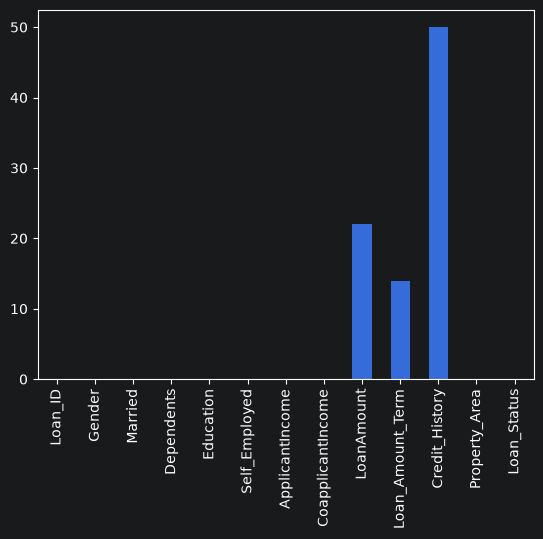

In [33]:
loan_data.isnull().sum().plot(kind='bar')

# Fixing Null values on LoanAmount Column

In [34]:
loan_data['LoanAmount']

0         NaN
1       128.0
2        66.0
3       120.0
4       141.0
        ...  
1609    323.0
1610    182.0
1611    222.0
1612    355.0
1613    463.0
Name: LoanAmount, Length: 1614, dtype: float64

In [35]:
loan_data['LoanAmount'].isnull().sum()

np.int64(22)

In [36]:
loan_data['LoanAmount'].max()

np.float64(700.0)

In [37]:
loan_data['LoanAmount'].min()

np.float64(9.0)

In [38]:
loan_data['LoanAmount'].mean()

np.float64(218.8467336683417)

In [39]:
loan_data['LoanAmount'].median()

np.float64(180.0)

<Axes: ylabel='LoanAmount'>

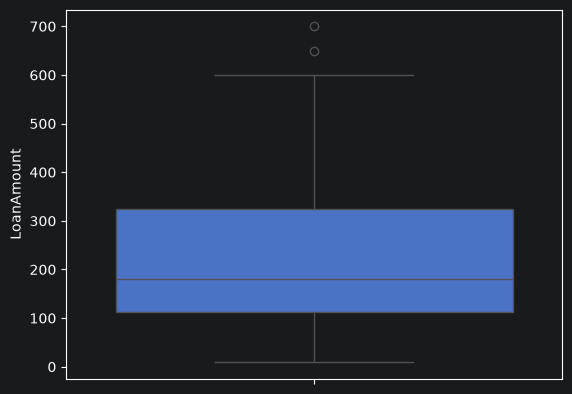

In [40]:
sns.boxplot(loan_data['LoanAmount'])

In [41]:
loan_data['LoanAmount'].dtype

dtype('float64')

In [42]:
loan_data['LoanAmount'].skew()

np.float64(0.6049680277273154)

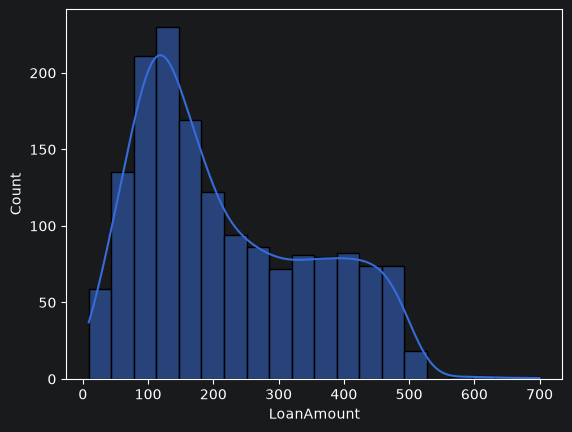

In [43]:
sns.histplot(loan_data['LoanAmount'], kde=True)
plt.show()

In [44]:
loan_data['LoanAmount'] =  loan_data['LoanAmount'].fillna(loan_data['LoanAmount'].median())

<Axes: >

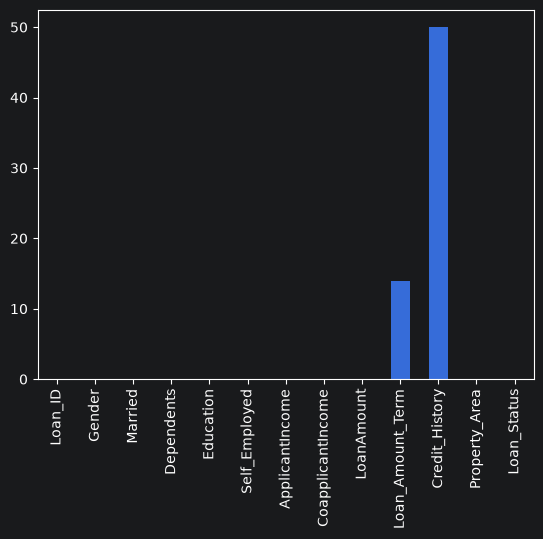

In [45]:
loan_data.isnull().sum().plot(kind="bar")

# Fixing Null values on Loan_Amount_Term Column

In [46]:
loan_data['Loan_Amount_Term']

0       360.0
1       360.0
2       360.0
3       360.0
4       360.0
        ...  
1609    180.0
1610    360.0
1611    360.0
1612    360.0
1613    240.0
Name: Loan_Amount_Term, Length: 1614, dtype: float64

In [47]:
loan_data['Loan_Amount_Term'].dtype

dtype('float64')

<Axes: xlabel='Loan_Amount_Term'>

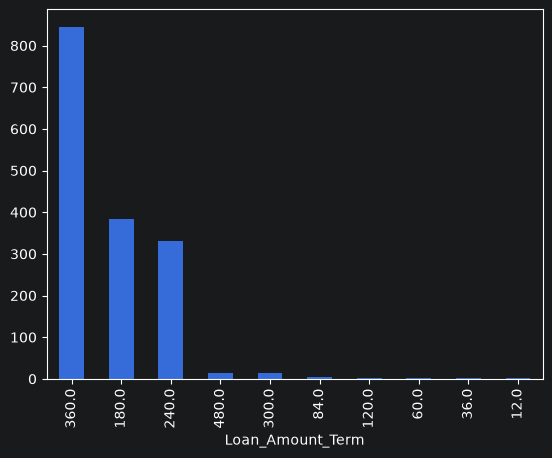

In [48]:
loan_data['Loan_Amount_Term'].value_counts().plot(kind="bar")

In [49]:
loan_data['Loan_Amount_Term'].mean()

np.float64(290.475)

In [50]:
loan_data['Loan_Amount_Term'].median()

np.float64(360.0)

<Axes: ylabel='Loan_Amount_Term'>

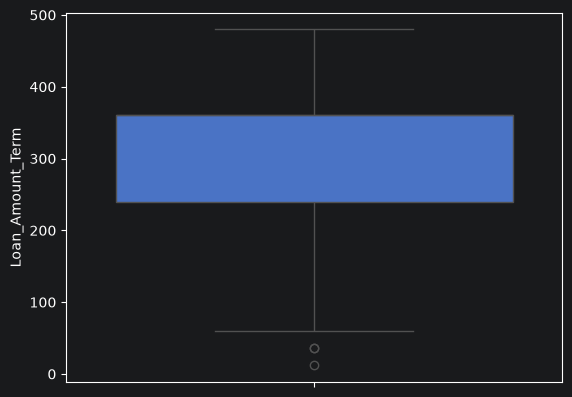

In [51]:
sns.boxplot(loan_data['Loan_Amount_Term'])

In [52]:
loan_data['Loan_Amount_Term'] =  loan_data['Loan_Amount_Term'].fillna(loan_data['Loan_Amount_Term'].median())

<Axes: >

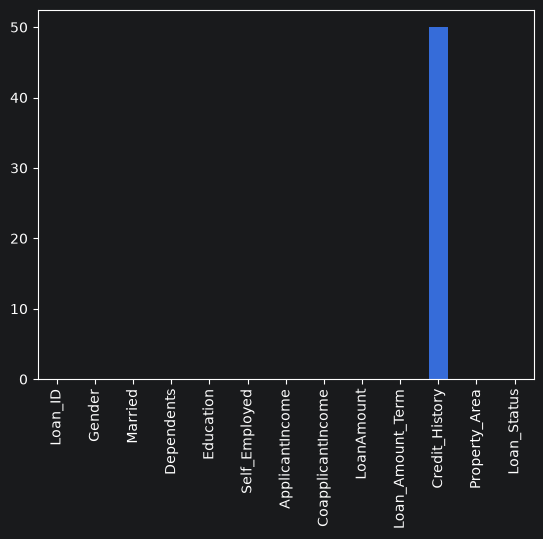

In [53]:
loan_data.isnull().sum().plot(kind='bar')

# Fixing Null values on Credit_History Column

In [54]:
loan_data['Credit_History']

0       1.0
1       1.0
2       1.0
3       1.0
4       1.0
       ... 
1609    0.0
1610    1.0
1611    0.0
1612    0.0
1613    1.0
Name: Credit_History, Length: 1614, dtype: float64

In [55]:
loan_data['Credit_History'].dtype

dtype('float64')

In [56]:
loan_data['Credit_History'].isnull().sum()

np.int64(50)

In [57]:
loan_data['Credit_History'].unique()

array([ 1.,  0., nan])

<Axes: xlabel='Credit_History'>

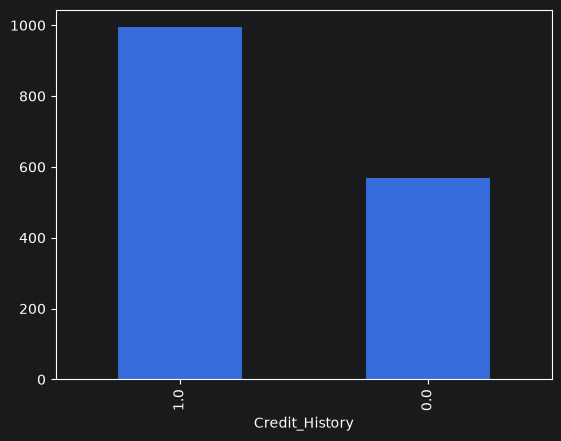

In [58]:
loan_data['Credit_History'].value_counts().plot(kind='bar')

In [59]:
loan_data['Credit_History'].mean()

np.float64(0.6355498721227621)

In [60]:
loan_data['Credit_History'].median()

np.float64(1.0)

In [61]:
loan_data['Credit_History'].mode()

0    1.0
Name: Credit_History, dtype: float64

In [62]:
loan_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,180.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1609,LP009965,Male,No,3+,Graduate,Yes,13658,9822.0,323.0,180.0,0.0,Urban,N
1610,LP009966,Male,Yes,0,Graduate,No,13683,2223.0,182.0,360.0,1.0,Semiurban,Y
1611,LP009970,Male,Yes,3+,Not Graduate,Yes,19409,768.0,222.0,360.0,0.0,Urban,N
1612,LP009977,Female,Yes,2,Graduate,Yes,8997,1354.0,355.0,360.0,0.0,Rural,Y


In [63]:
loan_data['Credit_History'] = loan_data['Credit_History'].fillna(loan_data['Credit_History'].mode()[0])

In [64]:
loan_data['Credit_History']

0       1.0
1       1.0
2       1.0
3       1.0
4       1.0
       ... 
1609    0.0
1610    1.0
1611    0.0
1612    0.0
1613    1.0
Name: Credit_History, Length: 1614, dtype: float64

<Axes: >

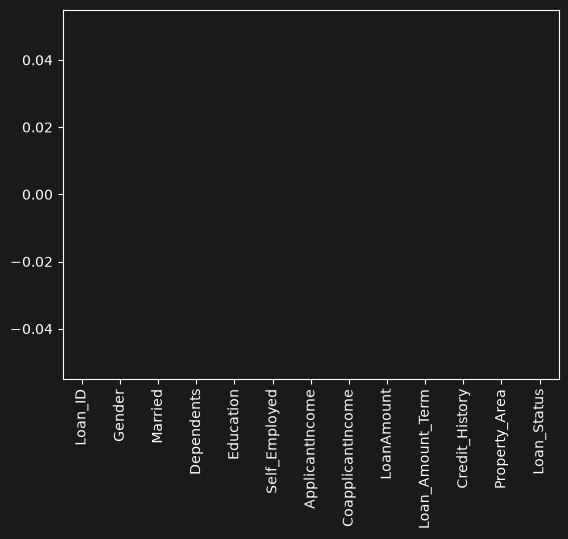

In [65]:
loan_data.isnull().sum().plot(kind="bar")

In [66]:
loan_data['Loan_ID'].unique()

<StringArray>
['LP001002', 'LP001003', 'LP001005', 'LP001006', 'LP001008', 'LP001011',
 'LP001013', 'LP001014', 'LP001018', 'LP001020',
 ...
 'LP009936', 'LP009940', 'LP009944', 'LP009954', 'LP009961', 'LP009965',
 'LP009966', 'LP009970', 'LP009977', 'LP009996']
Length: 1538, dtype: str

In [67]:
loan_data['Gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [68]:
loan_data['Married'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [69]:
loan_data['Dependents'].unique()

<StringArray>
['0', '1', '2', '3+']
Length: 4, dtype: str

In [70]:
loan_data['Education'].unique()

<StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str

In [71]:
loan_data['Self_Employed'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [72]:
loan_data['ApplicantIncome'].unique()

array([ 5849,  4583,  3000, ..., 19409,  8997, 19858], shape=(1455,))

In [73]:
loan_data['ApplicantIncome'].info()

<class 'pandas.Series'>
RangeIndex: 1614 entries, 0 to 1613
Series name: ApplicantIncome
Non-Null Count  Dtype
--------------  -----
1614 non-null   int64
dtypes: int64(1)
memory usage: 12.7 KB


In [74]:
loan_data['CoapplicantIncome'].unique()

array([   0., 1508., 2358., ...,  768., 1354., 6305.], shape=(1206,))

In [75]:
loan_data['LoanAmount'].info()

<class 'pandas.Series'>
RangeIndex: 1614 entries, 0 to 1613
Series name: LoanAmount
Non-Null Count  Dtype  
--------------  -----  
1614 non-null   float64
dtypes: float64(1)
memory usage: 12.7 KB


In [76]:
loan_data['Loan_Amount_Term'].unique()

array([360., 120., 240., 180.,  60., 300., 480.,  36.,  84.,  12.])

In [77]:
loan_data['Credit_History'].unique()

array([1., 0.])

In [78]:
loan_data['Property_Area'].unique()

<StringArray>
['Urban', 'Rural', 'Semiurban']
Length: 3, dtype: str

In [79]:
loan_data['Loan_Status'].unique()

<StringArray>
['Y', 'N']
Length: 2, dtype: str

# Adult DataSet

In [80]:
adult_data = pd.read_csv('adult.csv')

In [81]:
adult_data

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


<Axes: >

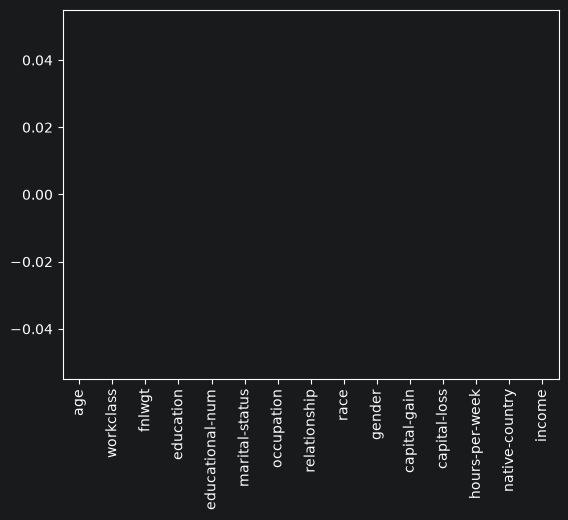

In [82]:
adult_data.isnull().sum().plot(kind="bar")

# AGE column

In [83]:
adult_data['age']

0        25
1        38
2        28
3        44
4        18
         ..
48837    27
48838    40
48839    58
48840    22
48841    52
Name: age, Length: 48842, dtype: int64

In [84]:
adult_data['age'].isnull().sum()

np.int64(0)

In [85]:
adult_data['age'].shape

(48842,)

In [86]:
adult_data['age']

0        25
1        38
2        28
3        44
4        18
         ..
48837    27
48838    40
48839    58
48840    22
48841    52
Name: age, Length: 48842, dtype: int64

In [87]:
adult_data['age'].dtype

dtype('int64')

# work class column

In [88]:
adult_data['workclass']

0             Private
1             Private
2           Local-gov
3             Private
4             Private
             ...     
48837         Private
48838         Private
48839         Private
48840         Private
48841    Self-emp-inc
Name: workclass, Length: 48842, dtype: str

In [89]:
adult_data['workclass'].unique()

<StringArray>
[         'Private',        'Local-gov', 'Self-emp-not-inc',
      'Federal-gov',        'State-gov',     'Self-emp-inc',
      'Without-pay',     'Never-worked']
Length: 8, dtype: str

In [90]:
adult_data['workclass'].mode()

0    Private
Name: workclass, dtype: str

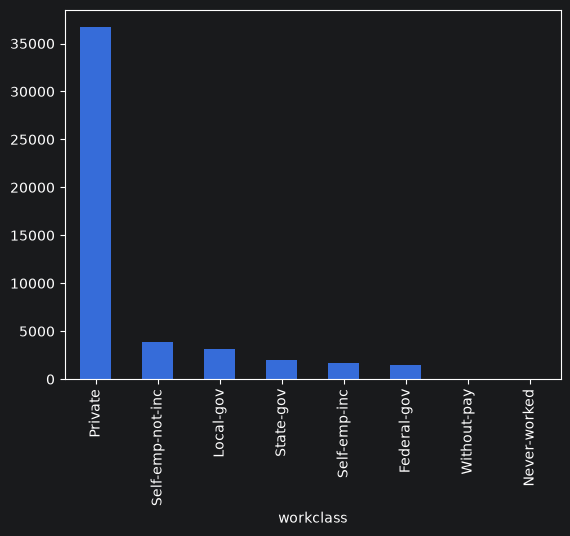

In [91]:
adult_data['workclass'].value_counts().plot(kind='bar')
plt.show()

In [92]:
workclass_mode = adult_data['workclass'].mode()[0]
adult_data['workclass'] = adult_data['workclass'].str.replace('?',workclass_mode)
adult_data.to_csv('adult.csv', index=False)

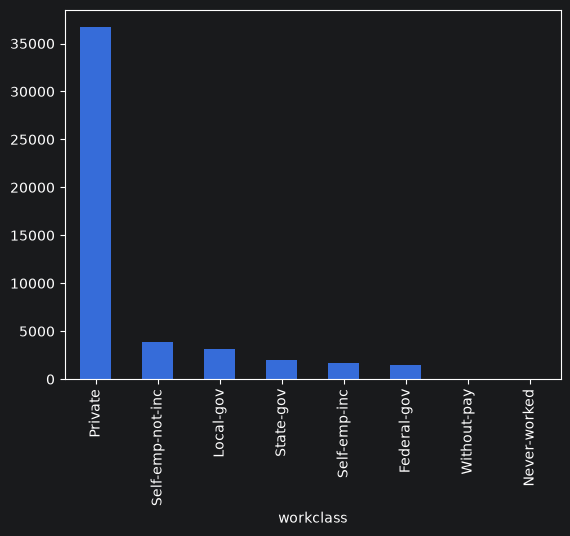

In [93]:
adult_data['workclass'].value_counts().plot(kind='bar')
plt.show()

In [94]:
adult_data['workclass'].dtype

<StringDtype(storage='python', na_value=nan)>

# fnlwgt(Final Weight in the Adult Census Income dataset) Column

In [95]:
adult_data['fnlwgt'].shape

(48842,)

In [96]:
adult_data['fnlwgt'].isnull().sum()

np.int64(0)

In [97]:
adult_data['fnlwgt'].dtype

dtype('int64')

In [98]:
adult_data['fnlwgt'].unique()

array([226802,  89814, 336951, ..., 129912, 255835, 257302],
      shape=(28523,))

<Axes: xlabel='fnlwgt', ylabel='Count'>

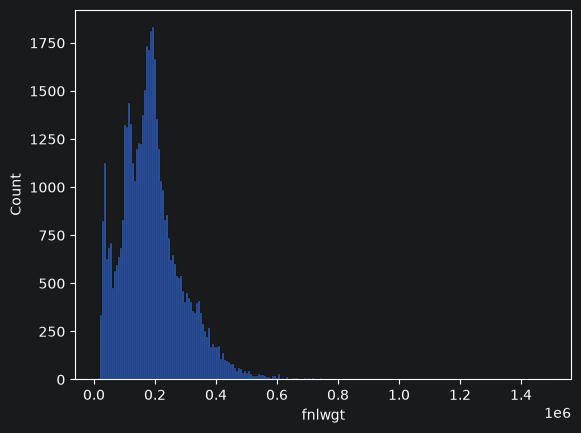

In [99]:
sns.histplot(adult_data['fnlwgt'])

In [100]:
adult_data['fnlwgt'].describe()

count    4.884200e+04
mean     1.896641e+05
std      1.056040e+05
min      1.228500e+04
25%      1.175505e+05
50%      1.781445e+05
75%      2.376420e+05
max      1.490400e+06
Name: fnlwgt, dtype: float64

# education column

In [101]:
adult_data['education'].isnull().sum()

np.int64(0)

In [102]:
adult_data['education'].unique()

<StringArray>
[        '11th',      'HS-grad',   'Assoc-acdm', 'Some-college',
         '10th',  'Prof-school',      '7th-8th',    'Bachelors',
      'Masters',    'Doctorate',      '5th-6th',    'Assoc-voc',
          '9th',         '12th',      '1st-4th',    'Preschool']
Length: 16, dtype: str

In [103]:
adult_data['education'].dtype

<StringDtype(storage='python', na_value=nan)>

<Axes: xlabel='education'>

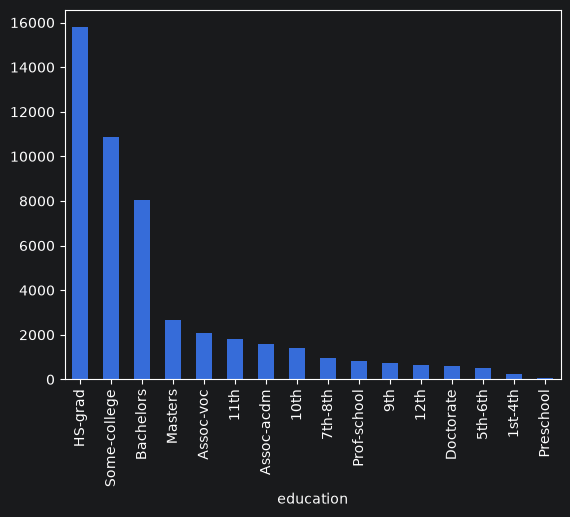

In [104]:
adult_data['education'].value_counts().plot(kind='bar')

# Educational Num

In [105]:
adult_data['educational-num'].isnull().sum()

np.int64(0)

In [106]:
adult_data['educational-num'].unique()

array([ 7,  9, 12, 10,  6, 15,  4, 13, 14, 16,  3, 11,  5,  8,  2,  1])

<Axes: ylabel='educational-num'>

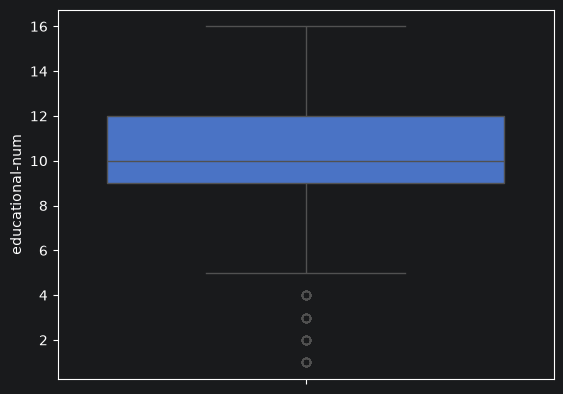

In [107]:
sns.boxplot(adult_data['educational-num'])

In [108]:
adult_data['educational-num'].dtype

dtype('int64')

In [111]:
adult_data['educational-num'].describe()

count    48842.000000
mean        10.078089
std          2.570973
min          1.000000
25%          9.000000
50%         10.000000
75%         12.000000
max         16.000000
Name: educational-num, dtype: float64

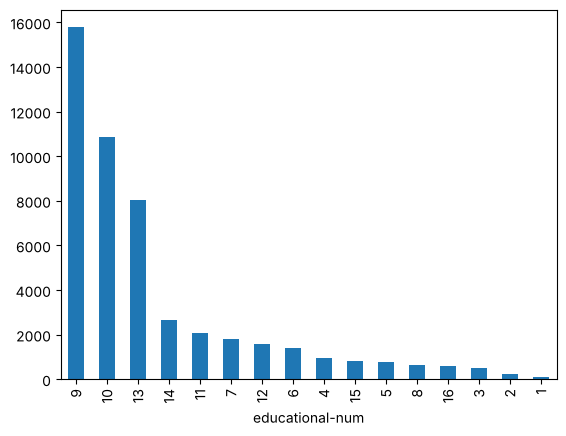

In [112]:
adult_data['educational-num'].value_counts().plot(kind='bar')
plt.show()

educational-num is just the number form of the education column and it has no null values so nothing to fix here

# marital-status column

In [113]:
adult_data['marital-status'].isnull().sum()

np.int64(0)

In [114]:
adult_data['marital-status'].dtype

<StringDtype(storage='python', na_value=nan)>

In [115]:
adult_data['marital-status'].unique()

<StringArray>
[        'Never-married',    'Married-civ-spouse',               'Widowed',
              'Divorced',             'Separated', 'Married-spouse-absent',
     'Married-AF-spouse']
Length: 7, dtype: str

In [116]:
adult_data['marital-status'].value_counts()

marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Married-AF-spouse           37
Name: count, dtype: int64

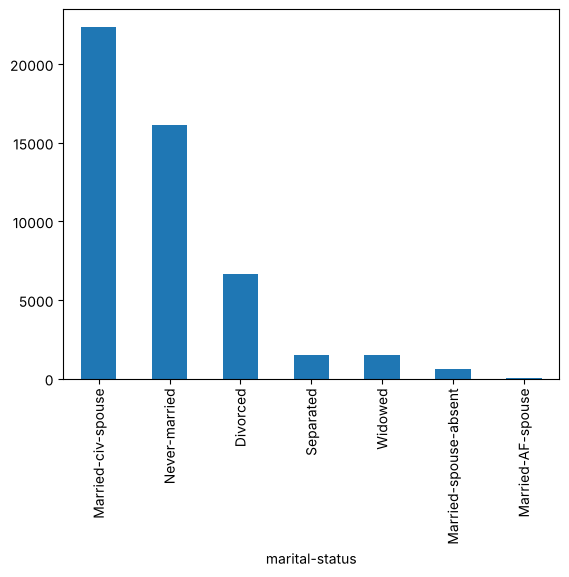

In [117]:
adult_data['marital-status'].value_counts().plot(kind='bar')
plt.show()

# occupation column

In [118]:
adult_data['occupation']

0        Machine-op-inspct
1          Farming-fishing
2          Protective-serv
3        Machine-op-inspct
4                        ?
               ...        
48837         Tech-support
48838    Machine-op-inspct
48839         Adm-clerical
48840         Adm-clerical
48841      Exec-managerial
Name: occupation, Length: 48842, dtype: str

In [119]:
adult_data['occupation'].isnull().sum()

np.int64(0)

In [120]:
adult_data['occupation'].dtype

<StringDtype(storage='python', na_value=nan)>

In [121]:
adult_data['occupation'].unique()

<StringArray>
['Machine-op-inspct',   'Farming-fishing',   'Protective-serv',
                 '?',     'Other-service',    'Prof-specialty',
      'Craft-repair',      'Adm-clerical',   'Exec-managerial',
      'Tech-support',             'Sales',   'Priv-house-serv',
  'Transport-moving', 'Handlers-cleaners',      'Armed-Forces']
Length: 15, dtype: str

isnull shows 0 but unique() shows there is a '?' in occupation, so these are the missing values

In [122]:
(adult_data['occupation'] == '?').sum()

np.int64(2809)

In [123]:
adult_data['occupation'].mode()

0    Prof-specialty
Name: occupation, dtype: str

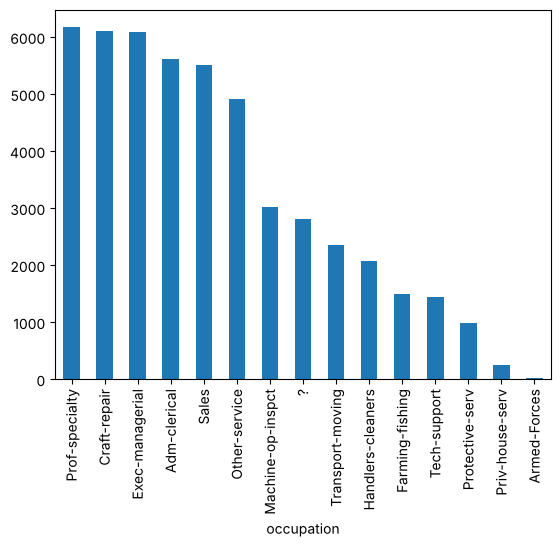

In [124]:
adult_data['occupation'].value_counts().plot(kind='bar')
plt.show()

In [125]:
occupation_mode = adult_data['occupation'].mode()[0]
adult_data['occupation'] = adult_data['occupation'].str.replace('?',occupation_mode)
adult_data.to_csv('adult.csv', index=False)

In [126]:
(adult_data['occupation'] == '?').sum()

np.int64(0)

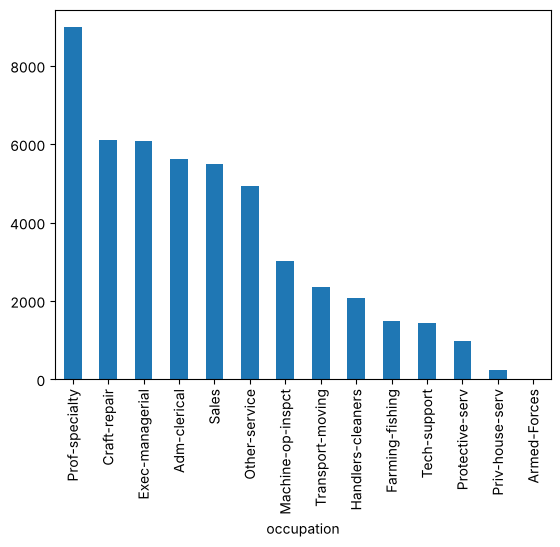

In [127]:
adult_data['occupation'].value_counts().plot(kind='bar')
plt.show()

In [128]:
adult_data['occupation'].dtype

<StringDtype(storage='python', na_value=nan)>

# relationship column

In [129]:
adult_data['relationship'].isnull().sum()

np.int64(0)

In [130]:
adult_data['relationship'].dtype

<StringDtype(storage='python', na_value=nan)>

In [131]:
adult_data['relationship'].unique()

<StringArray>
['Own-child', 'Husband', 'Not-in-family', 'Unmarried', 'Wife',
 'Other-relative']
Length: 6, dtype: str

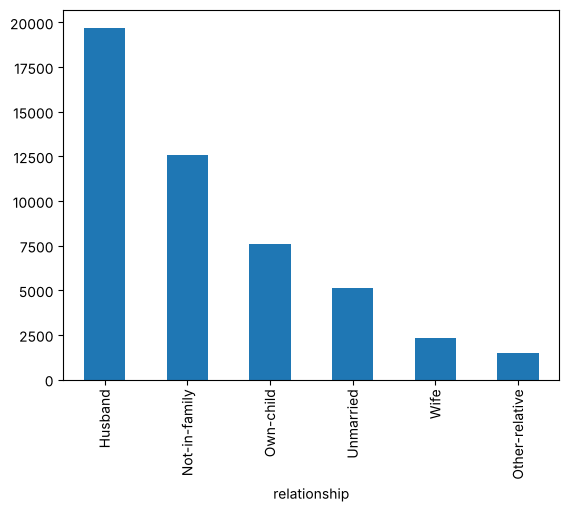

In [132]:
adult_data['relationship'].value_counts().plot(kind='bar')
plt.show()

# race column

In [133]:
adult_data['race'].isnull().sum()

np.int64(0)

In [134]:
adult_data['race'].dtype

<StringDtype(storage='python', na_value=nan)>

In [135]:
adult_data['race'].unique()

<StringArray>
['Black', 'White', 'Asian-Pac-Islander', 'Other', 'Amer-Indian-Eskimo']
Length: 5, dtype: str

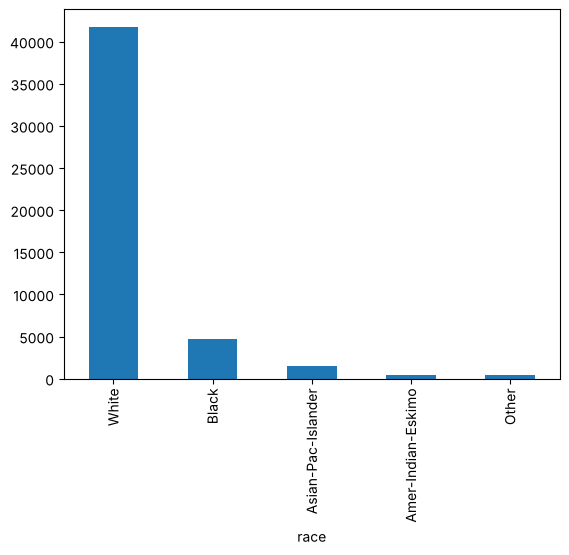

In [136]:
adult_data['race'].value_counts().plot(kind='bar')
plt.show()

# gender column

In [137]:
adult_data['gender'].isnull().sum()

np.int64(0)

In [138]:
adult_data['gender'].dtype

<StringDtype(storage='python', na_value=nan)>

In [139]:
adult_data['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

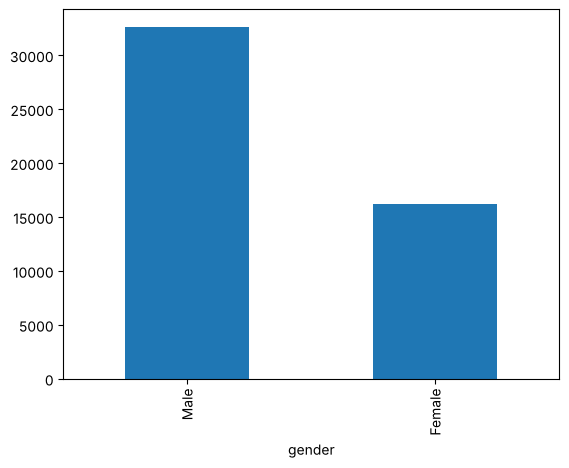

In [140]:
adult_data['gender'].value_counts().plot(kind='bar')
plt.show()

# capital-gain column

In [141]:
adult_data['capital-gain'].isnull().sum()

np.int64(0)

In [142]:
adult_data['capital-gain'].dtype

dtype('int64')

In [143]:
adult_data['capital-gain'].max()

np.int64(99999)

In [144]:
adult_data['capital-gain'].min()

np.int64(0)

In [145]:
adult_data['capital-gain'].mean()

np.float64(1079.0676262233324)

In [146]:
adult_data['capital-gain'].median()

np.float64(0.0)

In [147]:
adult_data['capital-gain'].skew()

np.float64(11.894658996587948)

In [148]:
(adult_data['capital-gain'] == 0).sum()

np.int64(44807)

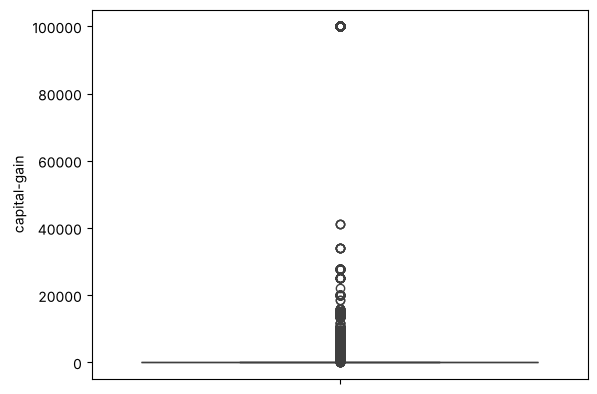

In [149]:
sns.boxplot(adult_data['capital-gain'])
plt.show()

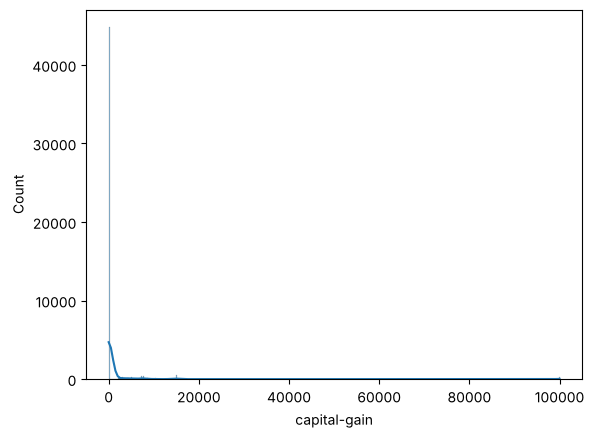

In [150]:
sns.histplot(adult_data['capital-gain'], kde=True)
plt.show()

most of the people have 0 capital gain so the data is very skewed, no nulls so nothing to fill

# capital-loss column

In [151]:
adult_data['capital-loss'].isnull().sum()

np.int64(0)

In [152]:
adult_data['capital-loss'].dtype

dtype('int64')

In [153]:
adult_data['capital-loss'].max()

np.int64(4356)

In [154]:
adult_data['capital-loss'].min()

np.int64(0)

In [155]:
adult_data['capital-loss'].mean()

np.float64(87.50231358257237)

In [156]:
adult_data['capital-loss'].median()

np.float64(0.0)

In [157]:
adult_data['capital-loss'].skew()

np.float64(4.569808857738484)

In [158]:
(adult_data['capital-loss'] == 0).sum()

np.int64(46560)

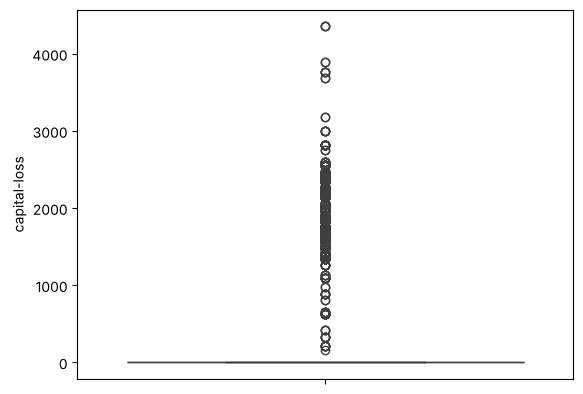

In [159]:
sns.boxplot(adult_data['capital-loss'])
plt.show()

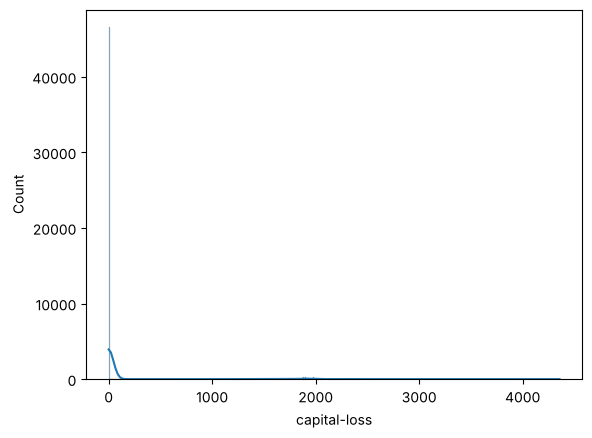

In [160]:
sns.histplot(adult_data['capital-loss'], kde=True)
plt.show()

# hours-per-week column

In [161]:
adult_data['hours-per-week'].isnull().sum()

np.int64(0)

In [162]:
adult_data['hours-per-week'].dtype

dtype('int64')

In [163]:
adult_data['hours-per-week'].max()

np.int64(99)

In [164]:
adult_data['hours-per-week'].min()

np.int64(1)

In [165]:
adult_data['hours-per-week'].mean()

np.float64(40.422382375824085)

In [166]:
adult_data['hours-per-week'].median()

np.float64(40.0)

In [167]:
adult_data['hours-per-week'].skew()

np.float64(0.2387496572027575)

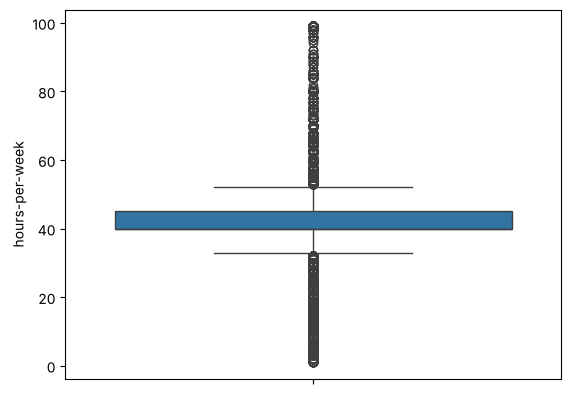

In [168]:
sns.boxplot(adult_data['hours-per-week'])
plt.show()

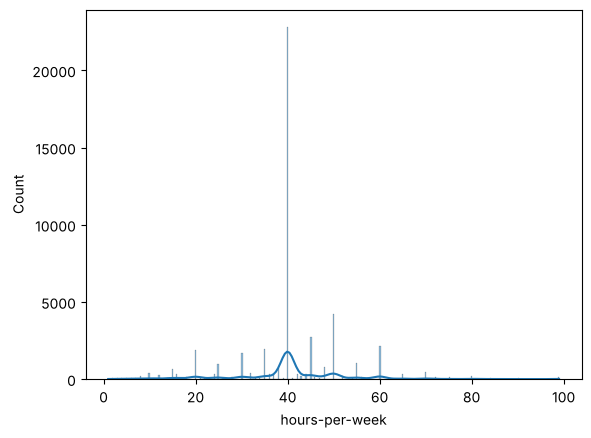

In [169]:
sns.histplot(adult_data['hours-per-week'], kde=True)
plt.show()

# native-country column

In [170]:
adult_data['native-country'].isnull().sum()

np.int64(0)

In [171]:
adult_data['native-country'].dtype

<StringDtype(storage='python', na_value=nan)>

In [172]:
adult_data['native-country'].unique()

<StringArray>
[             'United-States',                          '?',
                       'Peru',                  'Guatemala',
                     'Mexico',         'Dominican-Republic',
                    'Ireland',                    'Germany',
                'Philippines',                   'Thailand',
                      'Haiti',                'El-Salvador',
                'Puerto-Rico',                    'Vietnam',
                      'South',                   'Columbia',
                      'Japan',                      'India',
                   'Cambodia',                     'Poland',
                       'Laos',                    'England',
                       'Cuba',                     'Taiwan',
                      'Italy',                     'Canada',
                   'Portugal',                      'China',
                  'Nicaragua',                   'Honduras',
                       'Iran',                   'Scotland',
          

In [173]:
(adult_data['native-country'] == '?').sum()

np.int64(857)

In [174]:
adult_data['native-country'].mode()

0    United-States
Name: native-country, dtype: str

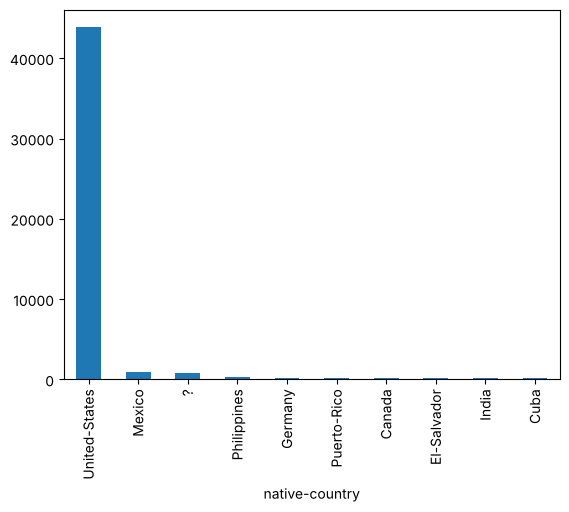

In [175]:
adult_data['native-country'].value_counts().head(10).plot(kind='bar')
plt.show()

In [176]:
country_mode = adult_data['native-country'].mode()[0]
adult_data['native-country'] = adult_data['native-country'].str.replace('?',country_mode)
adult_data.to_csv('adult.csv', index=False)

In [177]:
(adult_data['native-country'] == '?').sum()

np.int64(0)

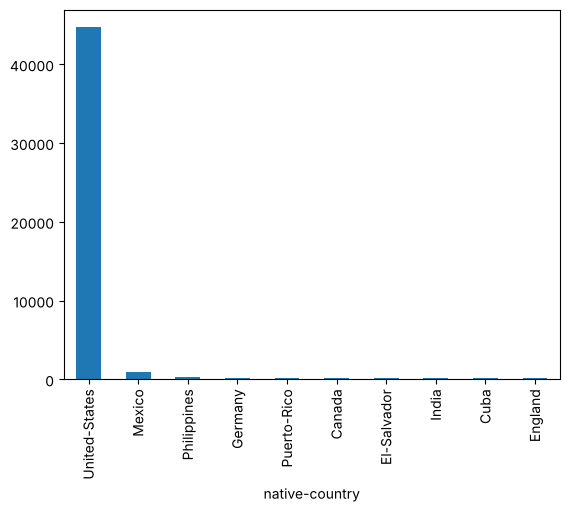

In [178]:
adult_data['native-country'].value_counts().head(10).plot(kind='bar')
plt.show()

# income column

In [179]:
adult_data['income'].isnull().sum()

np.int64(0)

In [180]:
adult_data['income'].dtype

<StringDtype(storage='python', na_value=nan)>

In [181]:
adult_data['income'].unique()

<StringArray>
['<=50K', '>50K']
Length: 2, dtype: str

In [182]:
adult_data['income'].value_counts()

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

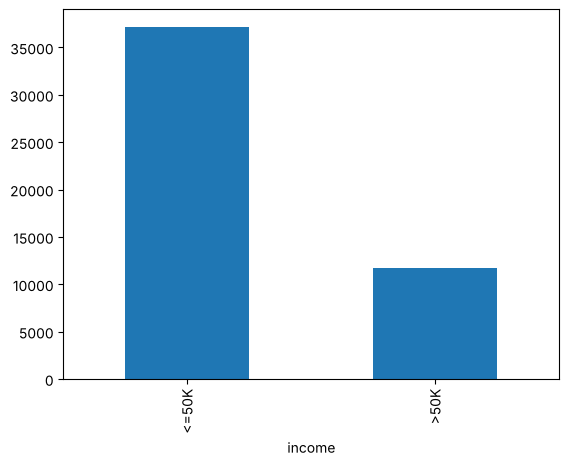

In [183]:
adult_data['income'].value_counts().plot(kind='bar')
plt.show()

# Duplicate rows

In [184]:
adult_data.duplicated().sum()

np.int64(53)

In [185]:
adult_data[adult_data.duplicated()]

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
864,24,Private,194630,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,35,United-States,<=50K
11189,37,Private,52870,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,<=50K
11212,29,Private,36440,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,40,United-States,<=50K
13848,30,Private,180317,Assoc-voc,11,Divorced,Machine-op-inspct,Not-in-family,White,Male,0,0,40,United-States,<=50K
15960,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
18476,39,Private,184659,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,<=50K
19399,19,Private,130431,5th-6th,3,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,36,Mexico,<=50K
19726,41,Private,116391,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,>50K
20606,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
21162,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K


In [186]:
adult_data = adult_data.drop_duplicates()
adult_data = adult_data.reset_index(drop=True)

In [187]:
adult_data.duplicated().sum()

np.int64(0)

In [188]:
adult_data.shape

(48789, 15)

In [189]:
adult_data.to_csv('adult.csv', index=False)

# Final check of Adult DataSet

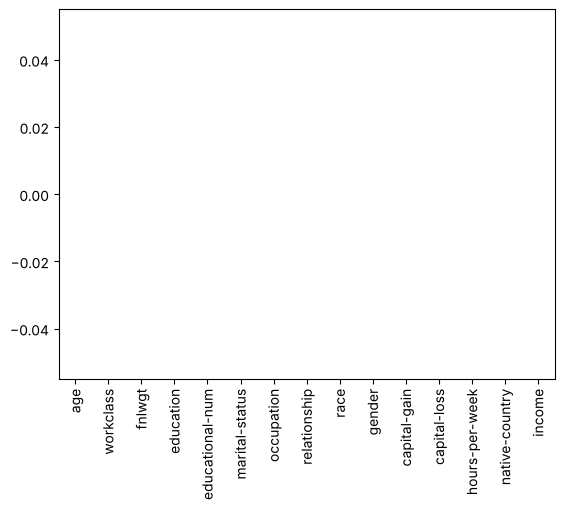

In [190]:
adult_data.isnull().sum().plot(kind='bar')
plt.show()

In [191]:
(adult_data == '?').sum().sum()

np.int64(0)

In [192]:
adult_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 48789 entries, 0 to 48788
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48789 non-null  int64
 1   workclass        48789 non-null  str  
 2   fnlwgt           48789 non-null  int64
 3   education        48789 non-null  str  
 4   educational-num  48789 non-null  int64
 5   marital-status   48789 non-null  str  
 6   occupation       48789 non-null  str  
 7   relationship     48789 non-null  str  
 8   race             48789 non-null  str  
 9   gender           48789 non-null  str  
 10  capital-gain     48789 non-null  int64
 11  capital-loss     48789 non-null  int64
 12  hours-per-week   48789 non-null  int64
 13  native-country   48789 non-null  str  
 14  income           48789 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [193]:
adult_data.head(30)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,103497,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K
6,29,Private,227026,HS-grad,9,Never-married,Prof-specialty,Unmarried,Black,Male,0,0,40,United-States,<=50K
7,63,Self-emp-not-inc,104626,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3103,0,32,United-States,>50K
8,24,Private,369667,Some-college,10,Never-married,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
9,55,Private,104996,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,10,United-States,<=50K


# Test Data (Excel file)

In [194]:
xl = pd.ExcelFile('test_data.xlsx')
xl.sheet_names

['Sheet1', 'Sheet2', 'Sheet3']

In [195]:
sheet1 = pd.read_excel('test_data.xlsx', sheet_name='Sheet1')
sheet2 = pd.read_excel('test_data.xlsx', sheet_name='Sheet2')
sheet3 = pd.read_excel('test_data.xlsx', sheet_name='Sheet3')

# Sheet1

In [196]:
sheet1

,sales_man_id,sales_man_name,sales_man_city,product_id,manager
0,1,Asad,Karachi,123,Jawed
1,2,Sumair,Lahore,123,Jawed
2,3,Farjad,Karachi,145,Najam
3,4,Hassan,Lahore,567,Najam
4,5,Nasir,Hyderabad,234,Jawed
5,6,Kashif,Hyderabad,234,Faisal
6,7,Sana,Lahore,567,Faisal
7,8,Fatima,Karachi,345,Najam
8,9,Abdullah,Karachi,123,Faisal


In [197]:
sheet1.shape

(9, 5)

In [198]:
sheet1.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   sales_man_id    9 non-null      int64
 1   sales_man_name  9 non-null      str  
 2   sales_man_city  9 non-null      str  
 3   product_id      9 non-null      int64
 4   manager         9 non-null      str  
dtypes: int64(2), str(3)
memory usage: 492.0 bytes


In [199]:
sheet1.isnull().sum()

sales_man_id      0
sales_man_name    0
sales_man_city    0
product_id        0
manager           0
dtype: int64

In [200]:
sheet1.duplicated().sum()

np.int64(0)

In [201]:
sheet1['sales_man_id'].duplicated().sum()

np.int64(0)

In [202]:
sheet1['sales_man_name'].unique()

<StringArray>
[    'Asad',   'Sumair',   'Farjad',   'Hassan',    'Nasir',   'Kashif',
     'Sana',   'Fatima', 'Abdullah']
Length: 9, dtype: str

In [203]:
sheet1['sales_man_city'].unique()

<StringArray>
['Karachi', 'Lahore', 'Hyderabad']
Length: 3, dtype: str

In [204]:
sheet1['product_id'].unique()

array([123, 145, 567, 234, 345])

In [205]:
sheet1['manager'].unique()

<StringArray>
['Jawed', 'Najam', 'Faisal']
Length: 3, dtype: str

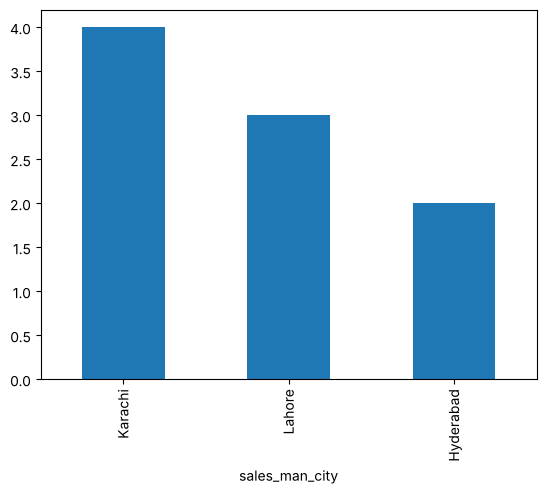

In [206]:
sheet1['sales_man_city'].value_counts().plot(kind='bar')
plt.show()

sheet1 is clean, no nulls and no duplicates

# Sheet2

In [207]:
sheet2

,sales_man_id,sales_man_name,sales_man_city,product_id,manager,Experience
0,1,Ahmed,Karachi,123,Jawed,2
1,22,Umer,Lahore,123,Jawed,3
2,33,Huzaifa,Karachi,145,Najam,4
3,4,Asad,Lahore,567,Najam,5
4,55,Hussain,Hyderabad,234,Jawed,6
5,66,Ali,Hyderabad,234,Faisal,7
6,77,Sadaf,Lahore,567,Faisal,8
7,88,Kiran,Karachi,345,Najam,9
8,99,Ali,Karachi,123,Faisal,1
9,101,Asad,Hyderabad,432,Jawed,4


In [208]:
sheet2.shape

(11, 6)

In [209]:
sheet2.info()

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   sales_man_id    11 non-null     int64
 1   sales_man_name  11 non-null     str  
 2   sales_man_city  11 non-null     str  
 3   product_id      11 non-null     int64
 4   manager         11 non-null     str  
 5   Experience      11 non-null     int64
dtypes: int64(3), str(3)
memory usage: 660.0 bytes


In [210]:
sheet2.isnull().sum()

sales_man_id      0
sales_man_name    0
sales_man_city    0
product_id        0
manager           0
Experience        0
dtype: int64

In [211]:
sheet2.duplicated().sum()

np.int64(0)

In [212]:
sheet2['sales_man_id'].duplicated().sum()

np.int64(1)

In [213]:
sheet2[sheet2['sales_man_id'].duplicated(keep=False)]

,sales_man_id,sales_man_name,sales_man_city,product_id,manager,Experience
9,101,Asad,Hyderabad,432,Jawed,4
10,101,Asad,Hyderabad,432,Jawed,5


sales_man_id 101 (Asad) is there two times, only the Experience is different (4 and 5). full row duplicate is 0 but the id is repeated so its a duplicate person. keeping the first row and dropping the second one

In [214]:
sheet2 = sheet2.drop_duplicates(subset='sales_man_id', keep='first')
sheet2 = sheet2.reset_index(drop=True)

In [215]:
sheet2['sales_man_id'].duplicated().sum()

np.int64(0)

In [216]:
sheet2.shape

(10, 6)

In [217]:
sheet2['sales_man_name'].unique()

<StringArray>
['Ahmed', 'Umer', 'Huzaifa', 'Asad', 'Hussain', 'Ali', 'Sadaf', 'Kiran']
Length: 8, dtype: str

In [218]:
sheet2['sales_man_city'].unique()

<StringArray>
['Karachi', 'Lahore', 'Hyderabad']
Length: 3, dtype: str

In [219]:
sheet2['manager'].unique()

<StringArray>
['Jawed', 'Najam', 'Faisal']
Length: 3, dtype: str

In [220]:
sheet2['Experience'].describe()

count    10.000000
mean      4.900000
std       2.601282
min       1.000000
25%       3.250000
50%       4.500000
75%       6.750000
max       9.000000
Name: Experience, dtype: float64

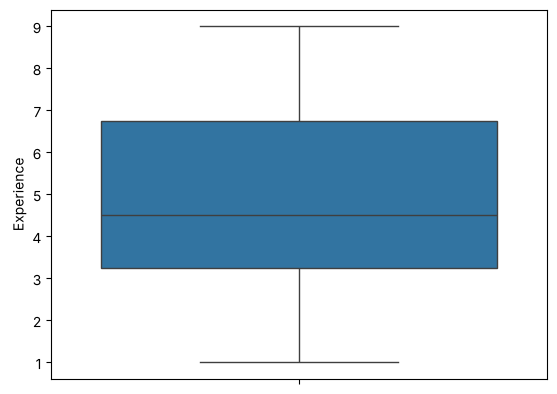

In [221]:
sns.boxplot(sheet2['Experience'])
plt.show()

Ali and Asad come more than once in the names but they have different ids so they are different people, leaving them as it is

# Sheet3

In [222]:
sheet3

,sales_man_name,Region,Sales,Amount
0,Asad,A,100,100000
1,Hussain,B,300,450000
2,Ali,C,234,125000
3,Sana,D,231,652000
4,Fatima,E,324,145000
5,Kashif,F,123,825000
6,Hassan,G,129,125000
7,Almas,H,345,325600
8,Farhan,I,400,895200


In [223]:
sheet3.columns

Index(['sales_man_name', 'Region ', 'Sales', 'Amount '], dtype='str')

the column names 'Region ' and 'Amount ' have extra space at the end, removing it so we can use the columns easily

In [224]:
sheet3 = sheet3.rename(columns={'Region ':'Region', 'Amount ':'Amount'})

In [225]:
sheet3.columns

Index(['sales_man_name', 'Region', 'Sales', 'Amount'], dtype='str')

In [226]:
sheet3.shape

(9, 4)

In [227]:
sheet3.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   sales_man_name  9 non-null      str  
 1   Region          9 non-null      str  
 2   Sales           9 non-null      int64
 3   Amount          9 non-null      int64
dtypes: int64(2), str(2)
memory usage: 420.0 bytes


In [228]:
sheet3.isnull().sum()

sales_man_name    0
Region            0
Sales             0
Amount            0
dtype: int64

In [229]:
sheet3.duplicated().sum()

np.int64(0)

In [230]:
sheet3['sales_man_name'].duplicated().sum()

np.int64(0)

In [231]:
sheet3['Region'].unique()

<StringArray>
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']
Length: 9, dtype: str

In [232]:
sheet3[['Sales','Amount']].describe()

,Sales,Amount
count,9.000000,9.000000
mean,242.888889,404755.555556
std,107.780384,316910.646362
min,100.000000,100000.000000
25%,129.000000,125000.000000
50%,234.000000,325600.000000
75%,324.000000,652000.000000
max,400.000000,895200.000000


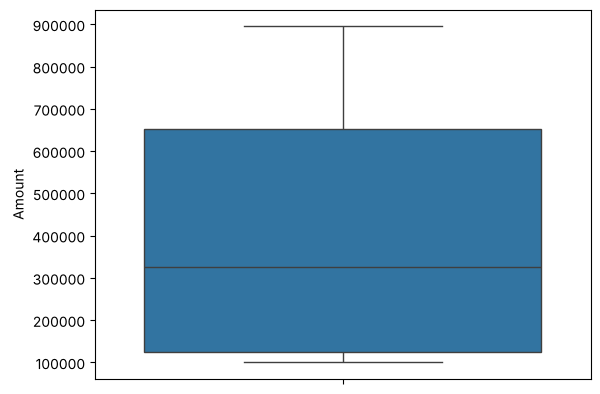

In [233]:
sns.boxplot(sheet3['Amount'])
plt.show()

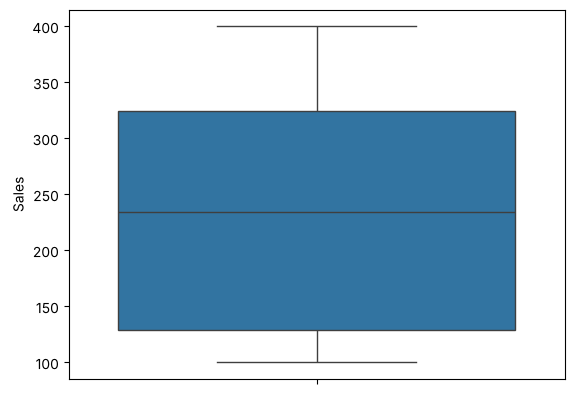

In [234]:
sns.boxplot(sheet3['Sales'])
plt.show()

# Final check of Test Data

In [235]:
sheet1.isnull().sum().sum(), sheet2.isnull().sum().sum(), sheet3.isnull().sum().sum()

(np.int64(0), np.int64(0), np.int64(0))

In [236]:
sheet1.shape, sheet2.shape, sheet3.shape

((9, 5), (10, 6), (9, 4))

In [237]:
with pd.ExcelWriter('test_data_cleaned.xlsx') as writer:
    sheet1.to_excel(writer, sheet_name='Sheet1', index=False)
    sheet2.to_excel(writer, sheet_name='Sheet2', index=False)
    sheet3.to_excel(writer, sheet_name='Sheet3', index=False)